# Student Performance Analysis Using Python

**King Khalid University**  
**College of Computer Science**  
**Department of Information Systems**  
**Course:** 2323 CIS – Introduction to Data Science  
**Group Number:** 2

## Team Members and Task Distribution

| No. | Student Name | Assigned Task |
|---|---|---|
| 1 | Bassel Saad Mohammed Alshahrani | Data Loading & Understanding |
| 2 | Nasser bin Hussein Alharbi Al-Faifi | Data Cleaning |
| 3 | Adi Mohammed Alkarimi Alamri | Data Transformation & Aggregation |
| 4 | Abdullah bin Ali Al Muqbil | Data Visualization |
| 5 | Faisal bin Nasser Alasmari | GitHub & Documentation |

## Project Objective

To analyze the relationships between study time, absences, previous grades, and students' final academic performance using Python and pandas.

## Dataset Source

**Dataset:** Student Performance Dataset  
**Provider:** UCI Machine Learning Repository  
**File:** student-mat.csv  
**Source:** https://archive.ics.uci.edu/dataset/320/student+performance

## Project Tools

Python, pandas, NumPy, Matplotlib, and Google Colab.

## Project Workflow

1. Data Loading & Understanding
2. Data Cleaning
3. Data Transformation & Aggregation
4. Data Visualization & Interpretation
5. GitHub Publishing & Documentation

In [4]:
from google.colab import files

uploaded = files.upload()

Saving student.zip to student.zip


In [5]:

import zipfile
import os

# Check the uploaded ZIP file
zip_path = "/content/student.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    print("Files inside ZIP:")
    print(archive.namelist())


Files inside ZIP:
['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']


In [6]:

import pandas as pd
import zipfile

# Load the mathematics student dataset
with zipfile.ZipFile("/content/student.zip", "r") as archive:
    with archive.open("student-mat.csv") as file:
        df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [7]:

# Part 1: Data Understanding

print("1. Dataset Shape:")
print(df.shape)

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. Data Types and Information:")
df.info()

print("\n4. Missing Values:")
print(df.isnull().sum())

print("\n5. Descriptive Statistics:")
display(df.describe(include="all"))


1. Dataset Shape:
(395, 33)

2. Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

3. Data Types and Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reas

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395,395,395.000000,395,395,395,395.000000,395.000000,395,395,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,349,208,NaN,307,281,354,NaN,NaN,141,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.696203,NaN,NaN,NaN,2.749367,2.521519,NaN,NaN,...,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,NaN,NaN,1.276043,NaN,NaN,NaN,1.094735,1.088201,NaN,NaN,...,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000


## Data Understanding – Results and Interpretation

The dataset contains 395 student records and 33 columns, including demographic, social, and academic information.

The dataset includes both numerical and categorical variables. Important academic variables include studytime, absences, G1, G2, and G3.

The missing-value analysis shows that all 33 columns contain zero missing values. Therefore, no missing-value imputation is required for the original dataset.

Descriptive statistics were generated for numerical and categorical variables to understand their distributions and characteristics.

The dataset is ready for the next stage, where duplicate records, data consistency, and possible cleaning requirements will be examined.

In [8]:

from google.colab import files

df.to_csv("student_performance_original.csv", index=False)

files.download("student_performance_original.csv")

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset downloaded successfully!
Dataset shape: (395, 33)


Part 2: Data Cleaning
In this section, we will clean the dataset by checking duplicate records, removing unnecessary spaces, and checking data consistency.
2.1 Checking Duplicate Records
2.2 Removing Unnecessary Spaces
2.3 Checking Data Consistency
Data Cleaning – Results and Interpretation

In [9]:
df_clean = df.copy()

duplicates_count = df_clean.duplicated().sum()
print("Number of duplicate rows:", duplicates_count)

if duplicates_count > 0:
    display(df_clean[df_clean.duplicated(keep=False)])
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate check:", df_clean.shape)

Number of duplicate rows: 0
Shape after duplicate check: (395, 33)


In [10]:
text_cols = df_clean.select_dtypes(include="object").columns

# count values that have extra spaces before cleaning
spaces_before = sum((df_clean[c] != df_clean[c].str.strip()).sum() for c in text_cols)
print("Values with extra spaces before cleaning:", spaces_before)

for c in text_cols:
    df_clean[c] = df_clean[c].str.strip()

# clean column names too
df_clean.columns = df_clean.columns.str.strip()

spaces_after = sum((df_clean[c] != df_clean[c].str.strip()).sum() for c in text_cols)
print("Values with extra spaces after cleaning:", spaces_after)

Values with extra spaces before cleaning: 0
Values with extra spaces after cleaning: 0


In [11]:
# 1) Categorical columns: check the unique values
for c in df_clean.select_dtypes(include="object").columns:
    print(f"{c}: {sorted(df_clean[c].unique())}")

# 2) Numeric columns: check values are within the valid ranges
ranges = {
    "age": (15, 22),
    "Medu": (0, 4), "Fedu": (0, 4),
    "traveltime": (1, 4), "studytime": (1, 4),
    "failures": (0, 4),
    "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, 93),
    "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}
for col, (lo, hi) in ranges.items():
    invalid = df_clean[(df_clean[col] < lo) | (df_clean[col] > hi)]
    print(f"{col}: invalid values = {len(invalid)}")

# 3) Logical check: students with G3 = 0
zero_g3 = (df_clean["G3"] == 0).sum()
print("Students with final grade G3 = 0:", zero_g3)

# 4) Outliers in absences (reported only, not removed)
q1, q3 = df_clean["absences"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df_clean[df_clean["absences"] > q3 + 1.5 * iqr]
print("Absences outliers (IQR):", len(outliers))

print("Final shape:", df_clean.shape)

school: ['GP', 'MS']
sex: ['F', 'M']
address: ['R', 'U']
famsize: ['GT3', 'LE3']
Pstatus: ['A', 'T']
Mjob: ['at_home', 'health', 'other', 'services', 'teacher']
Fjob: ['at_home', 'health', 'other', 'services', 'teacher']
reason: ['course', 'home', 'other', 'reputation']
guardian: ['father', 'mother', 'other']
schoolsup: ['no', 'yes']
famsup: ['no', 'yes']
paid: ['no', 'yes']
activities: ['no', 'yes']
nursery: ['no', 'yes']
higher: ['no', 'yes']
internet: ['no', 'yes']
romantic: ['no', 'yes']
age: invalid values = 0
Medu: invalid values = 0
Fedu: invalid values = 0
traveltime: invalid values = 0
studytime: invalid values = 0
failures: invalid values = 0
famrel: invalid values = 0
freetime: invalid values = 0
goout: invalid values = 0
Dalc: invalid values = 0
Walc: invalid values = 0
health: invalid values = 0
absences: invalid values = 0
G1: invalid values = 0
G2: invalid values = 0
G3: invalid values = 0
Students with final grade G3 = 0: 38
Absences outliers (IQR): 15
Final shape: (395

### Data Cleaning – Results and Interpretation

The data cleaning stage showed that the dataset is of good quality. The duplicate check found 0 duplicate records, so no rows were removed. The check for unnecessary spaces found 0 values with extra spaces in the text columns and column names, so no changes were needed.

The consistency check showed that all categorical columns contain only valid and consistent values (for example: GP/MS for school, F/M for sex, and yes/no for the binary columns). All numerical columns were also within their expected ranges, with 0 invalid values in every column.

The logical check found 38 students with a final grade (G3) equal to 0, and the IQR method detected 15 outliers in the absences column. These records were kept and not removed because they represent real cases (such as students who did not take the final exam or have high absences) and not data-entry errors, and removing them could affect the analysis.

After cleaning, the dataset remained at 395 records and 33 columns, and it is ready for the next stage: Data Transformation and Aggregation.

In [12]:
df_clean.to_csv("student_performance_cleaned.csv", index=False)
from google.colab import files
files.download("student_performance_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Data Transformation & Aggregation

1. Import Libraries and Copy Dataset

In [13]:

import pandas as pd
import numpy as np

df = df_clean.copy()
print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (395, 33)


2. Create New Analytical Columns

In [14]:

# Calculate the average grade for each student
df['Average'] = (df['G1'] + df['G2'] + df['G3']) / 3

# Classify students based on their final grade
df['Final_Result'] = np.where(df['G3'] >= 10, 'Pass', 'Fail')

# Classify students according to study time
df['Study_Level'] = np.where(
    df['studytime'] <= 2, 'Low', 'High'
)

# Classify students according to absence levels
df['Absence_Level'] = pd.cut(
    df['absences'],
    bins=[-1, 4, 10, float('inf')],
    labels=['Low', 'Medium', 'High']
)

print("New Analytical Columns:")
display(df[['G1', 'G2', 'G3', 'Average',
            'Final_Result', 'Study_Level',
            'Absence_Level']].head())


New Analytical Columns:


,G1,G2,G3,Average,Final_Result,Study_Level,Absence_Level
0,5,6,6,5.666667,Fail,Low,Medium
1,5,5,6,5.333333,Fail,Low,Low
2,7,8,10,8.333333,Pass,Low,Medium
3,15,14,15,14.666667,Pass,High,Low
4,6,10,10,8.666667,Pass,Low,Low


3. Data Aggregation – Average Grades by Gender

In [15]:

gender_avg = df.groupby('sex')[
    ['G1', 'G2', 'G3', 'Average']
].mean()

print("Average Grades by Gender:")
display(gender_avg)


Average Grades by Gender:


,G1,G2,G3,Average
sex,,,,
F,10.620192,10.389423,9.966346,10.325321
M,11.229947,11.074866,10.914439,11.073084


4. Data Aggregation – Average Grades by Study Time

In [16]:

study_avg = df.groupby('studytime')[
    ['G1', 'G2', 'G3', 'Average']
].mean()

print("Average Grades by Study Time:")
display(study_avg)


Average Grades by Study Time:


,G1,G2,G3,Average
studytime,,,,
1,10.438095,10.276190,10.047619,10.253968
2,10.651515,10.505051,10.171717,10.442761
3,12.046154,11.507692,11.400000,11.651282
4,11.888889,12.037037,11.259259,11.728395


5. Average Absences by Gender

In [17]:

absence_avg = df.groupby('sex')['absences'].mean()

print("Average Absences by Gender:")
display(absence_avg)


Average Absences by Gender:


,absences
sex,
F,6.216346
M,5.144385


6. Pass and Fail Students Count

In [18]:

result_counts = df['Final_Result'].value_counts()

print("Pass and Fail Students:")
display(result_counts)


Pass and Fail Students:


,count
Final_Result,
Pass,265
Fail,130


7. Distribution of Study and Absence Levels

In [19]:

print("Study Level Distribution:")
display(df['Study_Level'].value_counts())

print("Absence Level Distribution:")
display(df['Absence_Level'].value_counts())


Study Level Distribution:


,count
Study_Level,
Low,303
High,92


Absence Level Distribution:


,count
Absence_Level,
Low,244
Medium,85
High,66


8. Average Grades by Absence Level

In [20]:

absence_grade_avg = df.groupby(
    'Absence_Level', observed=True
)['Average'].mean()

print("Average Grades by Absence Level:")
display(absence_grade_avg)


Average Grades by Absence Level:


,Average
Absence_Level,
Low,10.613388
Medium,11.176471
High,10.282828


9. Descriptive Statistics for New Columns

In [21]:

print("Summary Statistics:")
display(df[['Average', 'absences', 'studytime']].describe())


Summary Statistics:


,Average,absences,studytime
count,395.000000,395.000000,395.000000
mean,10.679325,5.708861,2.035443
std,3.696786,8.003096,0.839240
min,1.333333,0.000000,1.000000
25%,8.333333,0.000000,1.000000
50%,10.666667,4.000000,2.000000
75%,13.333333,8.000000,2.000000
max,19.333333,75.000000,4.000000


In [22]:

# Calculate pass rate according to study time
pass_rate = df.groupby('studytime').apply(
    lambda group: (group['Final_Result'] == 'Pass').mean() * 100,
    include_groups=False
)

print("Pass Rate by Study Time (%):")
display(pass_rate)


Pass Rate by Study Time (%):


,0
studytime,
1,64.761905
2,64.646465
3,75.384615
4,74.074074


In [23]:

print("Original Dataset:", df_clean.shape)
print("Transformed Dataset:", df.shape)

assert len(df) == len(df_clean), "Number of records changed!"
assert df.shape[1] == 37, "Unexpected number of columns!"

print("Transformation completed successfully!")


Original Dataset: (395, 33)
Transformed Dataset: (395, 37)
Transformation completed successfully!


10. Final Dataset and Save

In [24]:

print("Final Dataset:")
display(df.head())

print("Final Dataset Shape:", df.shape)

print("Final Dataset Columns:")
print(df.columns.tolist())

df.to_csv('transformed_students.csv', index=False)

print("Transformed dataset saved successfully.")


Final Dataset:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Walc,health,absences,G1,G2,G3,Average,Final_Result,Study_Level,Absence_Level
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,3,6,5,6,6,5.666667,Fail,Low,Medium
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,3,4,5,5,6,5.333333,Fail,Low,Low
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,3,10,7,8,10,8.333333,Pass,Low,Medium
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,5,2,15,14,15,14.666667,Pass,High,Low
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,5,4,6,10,10,8.666667,Pass,Low,Low


Final Dataset Shape: (395, 37)
Final Dataset Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'Average', 'Final_Result', 'Study_Level', 'Absence_Level']
Transformed dataset saved successfully.


## Data Transformation & Aggregation – Results and Interpretation

We created four new columns: `Average` (mean of G1, G2, G3), `Final_Result` (Pass if G3 ≥ 10, otherwise Fail), `Study_Level` (Low if studytime ≤ 2, otherwise High) and `Absence_Level` (Low: 0–4, Medium: 5–10, High: more than 10 absences). The dataset now has 395 rows and 37 columns.

**Pass and fail:** 265 students passed (67.1%) and 130 failed (32.9%). Most students have a Low study level (303 vs. 92) and Low absences (244 Low, 85 Medium, 66 High).

**Gender:** Males have a higher average grade than females (11.07 vs. 10.33), and females have more absences (6.22 vs. 5.14).

**Study time:** The average grade goes up with study time: 10.25, 10.44, 11.65 and 11.73 for levels 1 to 4. The pass rate also goes up, from about 65% (levels 1–2) to about 75% (levels 3–4). The increase is small, so study time helps but is not the only factor.

**Absences:** Medium absences had the highest average (11.18), compared to Low (10.61) and High (10.28). This is because the 38 students with G3 = 0 all have 0 absences, so they lower the Low group's average. Without them, the averages are Low 11.82, Medium 11.18 and High 10.28, so grades decrease as absences increase. The pass rate for High absences is also lower (54.5% vs. about 69–72%).

**Conclusion:** More study time is linked to higher grades, and many absences are linked to lower grades. The G3 = 0 students were kept because they are real cases, but they should be considered when reading the results. These are relationships, not proof of cause. The final dataset `transformed_students.csv` is ready for visualization.

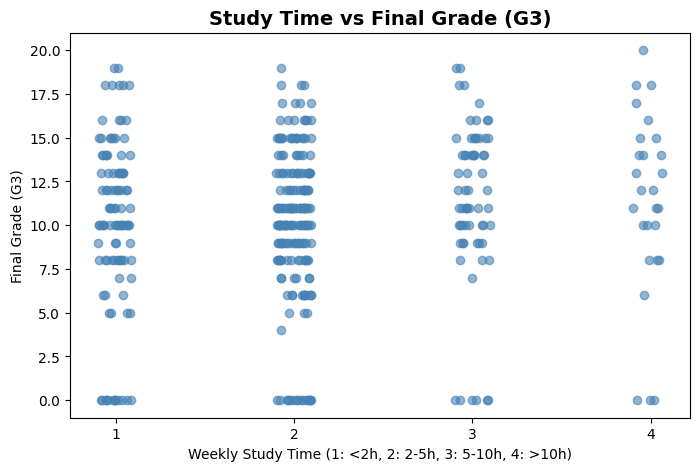

Interpretation 1:
The scatter plot indicates a positive relationship where students who dedicate more weekly study hours tend to achieve higher final grades (G3).
----------------------------------------------------------------------


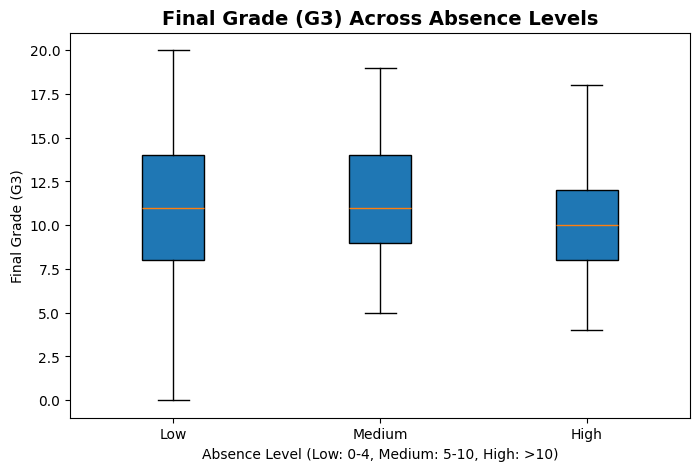

Mean G3 -> Low: 10.14 | Medium: 11.41 | High: 10.15
Interpretation 2:
The box plot compares final grades across absence levels. Students with G3 = 0 all have 0 absences, which lowers the Low group, so this pattern should be read with that in mind.
----------------------------------------------------------------------


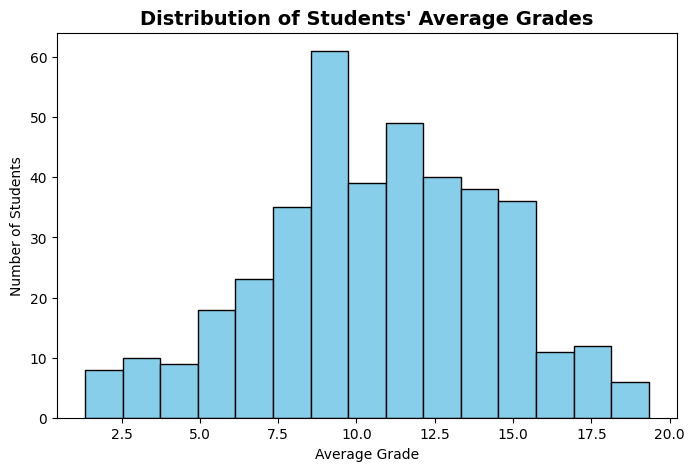

Interpretation 3:
The histogram shows that the overall student averages follow a near-normal distribution, centered around the middle passing grade range.
----------------------------------------------------------------------


In [25]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- Chart 1: Study Time vs Final Grade ----------
plt.figure(figsize=(8, 5))
jitter = np.random.default_rng(42).uniform(-0.1, 0.1, len(df))
plt.scatter(df['studytime'] + jitter, df['G3'], alpha=0.6, color='steelblue')
plt.title('Study Time vs Final Grade (G3)', fontsize=14, fontweight='bold')
plt.xlabel('Weekly Study Time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)')
plt.ylabel('Final Grade (G3)')
plt.xticks([1, 2, 3, 4])
plt.show()

print('Interpretation 1:')
print('The scatter plot indicates a positive relationship where students who '
      'dedicate more weekly study hours tend to achieve higher final grades (G3).')
print('-' * 70)

# ---------- Chart 2: Final Grade Across Absence Levels ----------
order = ['Low', 'Medium', 'High']
data = [df[df['Absence_Level'] == lvl]['G3'] for lvl in order]

plt.figure(figsize=(8, 5))
plt.boxplot(data, patch_artist=True)
plt.xticks([1, 2, 3], order)
plt.title('Final Grade (G3) Across Absence Levels', fontsize=14, fontweight='bold')
plt.xlabel('Absence Level (Low: 0-4, Medium: 5-10, High: >10)')
plt.ylabel('Final Grade (G3)')
plt.show()

means = df.groupby('Absence_Level', observed=True)['G3'].mean()
print('Mean G3 -> Low: {:.2f} | Medium: {:.2f} | High: {:.2f}'.format(
    means['Low'], means['Medium'], means['High']))
print('Interpretation 2:')
print('The box plot compares final grades across absence levels. Students with '
      'G3 = 0 all have 0 absences, which lowers the Low group, so this pattern '
      'should be read with that in mind.')
print('-' * 70)

# ---------- Chart 3: Distribution of Average Grades ----------
plt.figure(figsize=(8, 5))
plt.hist(df['Average'], bins=15, color='skyblue', edgecolor='black')
plt.title("Distribution of Students' Average Grades", fontsize=14, fontweight='bold')
plt.xlabel('Average Grade')
plt.ylabel('Number of Students')
plt.show()

print('Interpretation 3:')
print('The histogram shows that the overall student averages follow a '
      'near-normal distribution, centered around the middle passing grade range.')
print('-' * 70)